# Hand-Coded MNIST: A Neural Network From Scratch

Welcome! This notebook is the companion to the MJNLAB blog post **Applied ML: A Beginner's Guide to Supervised Learning**.

We are going to teach a computer to read handwritten digits (0 to 9). No TensorFlow, no PyTorch. Just **NumPy** and a bit of maths, so you can see every single moving part.

**The plan:**
1. Load and look at the data
2. Prepare it for the model
3. Build a small neural network by hand
4. Teach it (training)
5. Test it on images it has never seen
6. Poke at it and try things yourself

> Run the cells from top to bottom with `Shift + Enter`. Everything should finish in a few minutes on a normal laptop.

## 0. Setup

The only things we need are NumPy (for maths) and Matplotlib (for pictures).
If you started this notebook with `uv run jupyter lab`, they are already installed for you.

In [1]:
import os
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

# A fixed seed means you get the same "random" numbers as me, so results match the post
rng = np.random.default_rng(seed=42)

## 1. Load the Data

MNIST is a classic dataset of 70 000 small grayscale images of handwritten digits, each 28 by 28 pixels.
Every image comes with a **label**: the digit it actually shows. Images plus correct answers is exactly what makes this **supervised learning**.

The first time you run the cell below, it downloads the dataset to `data/mnist.npz`. After that, it just loads the file.

In [2]:
DATA_PATH = "data/mnist.npz"
DATA_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    print("Downloading MNIST...")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

with np.load(DATA_PATH) as data:
    X_train_raw, y_train_raw = data["x_train"], data["y_train"]
    X_test_raw, y_test_raw = data["x_test"], data["y_test"]

print("Training images:", X_train_raw.shape)  # (60000, 28, 28)
print("Test images:    ", X_test_raw.shape)   # (10000, 28, 28)

Training images: (60000, 28, 28)
Test images:     (10000, 28, 28)


### Take a look

Always look at your data before doing anything clever with it. Let's plot a few images with their labels.

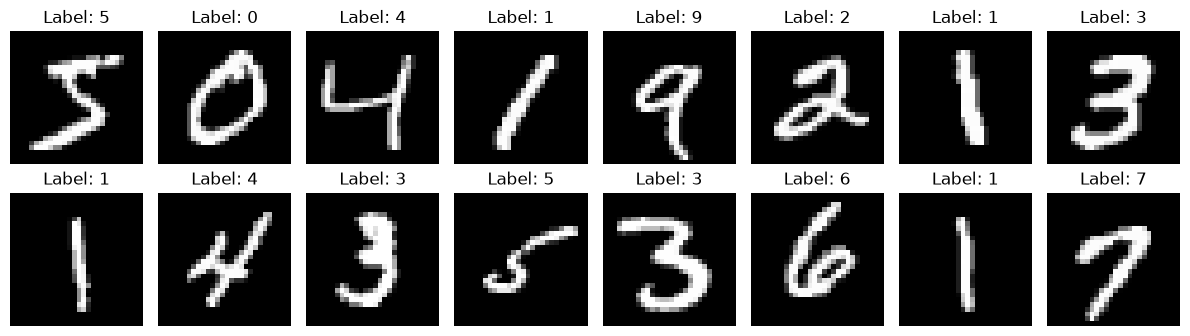

Pixel values go from 0 to 255
Images per digit: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [3]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, label in zip(axes.flat, X_train_raw[:16], y_train_raw[:16]):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Pixel values go from", X_train_raw.min(), "to", X_train_raw.max())
print("Images per digit:", np.bincount(y_train_raw))

To the computer, an image is just a grid of numbers. `0` is black, `255` is white. Our job is to find a function that turns those 784 numbers into the right digit.

## 2. Prepare the Data

Three small steps:

1. **Flatten**: turn each 28x28 grid into one long row of 784 numbers. Our simple network does not care about rows and columns.
2. **Scale**: divide by 255 so every pixel is between 0 and 1. Small, similar-sized numbers make training much more stable.
3. **One-hot encode** the labels: the digit `3` becomes `[0,0,0,1,0,0,0,0,0,0]`. This matches the 10 outputs of our network, one per digit.

We also hold back 5 000 training images as a **validation set**. We never train on these. They tell us how the model does on unseen data while we are still tweaking things, so the real test set stays untouched until the very end.

In [4]:
def preprocess(X):
    return X.reshape(len(X), -1).astype(np.float32) / 255.0

def one_hot(y, num_classes=10):
    out = np.zeros((len(y), num_classes), dtype=np.float32)
    out[np.arange(len(y)), y] = 1.0
    return out

X_all = preprocess(X_train_raw)
X_test = preprocess(X_test_raw)
y_test = y_test_raw

# Shuffle once, then split off a validation set
idx = rng.permutation(len(X_all))
val_idx, train_idx = idx[:5000], idx[5000:]

X_train, y_train = X_all[train_idx], y_train_raw[train_idx]
X_val, y_val = X_all[val_idx], y_train_raw[val_idx]
Y_train = one_hot(y_train)

print("Train:", X_train.shape, " Validation:", X_val.shape, " Test:", X_test.shape)
print("Label", y_train[0], "as one-hot:", Y_train[0])

Train: (55000, 784)  Validation: (5000, 784)  Test: (10000, 784)
Label 6 as one-hot: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


## 3. Build the Network

Our network has three layers:

```
784 pixels  ->  128 hidden neurons (ReLU)  ->  10 outputs (softmax)
```

- Each layer does `output = input @ W + b`: multiply by a matrix of **weights** `W`, add a **bias** `b`. These are the numbers the model learns.
- **ReLU** (`max(0, x)`) is the bend in the road. Without it, stacking layers would just be one big straight line, and straight lines can't read handwriting.
- **Softmax** turns the 10 raw output scores into probabilities that add up to 1. The biggest one is the model's guess.

We start the weights as small random numbers. If they all started equal, every neuron would learn the same thing.

In [5]:
def init_params(n_in=784, n_hidden=128, n_out=10):
    # "He initialisation": random numbers scaled to fit ReLU nicely
    return {
        "W1": rng.normal(0, np.sqrt(2 / n_in), size=(n_in, n_hidden)).astype(np.float32),
        "b1": np.zeros(n_hidden, dtype=np.float32),
        "W2": rng.normal(0, np.sqrt(2 / n_hidden), size=(n_hidden, n_out)).astype(np.float32),
        "b2": np.zeros(n_out, dtype=np.float32),
    }

def relu(z):
    return np.maximum(0, z)

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)  # subtract the max so exp() never overflows
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def forward(params, X):
    z1 = X @ params["W1"] + params["b1"]
    a1 = relu(z1)
    z2 = a1 @ params["W2"] + params["b2"]
    probs = softmax(z2)
    cache = (X, z1, a1)  # remember these, we need them when learning
    return probs, cache

params = init_params()
n_params = sum(p.size for p in params.values())
print(f"The network has {n_params:,} numbers to learn")

The network has 101,770 numbers to learn


Before training, the network is just guessing. With 10 digits, a random guess is right about 10% of the time. Let's confirm:

In [6]:
def accuracy(params, X, y):
    probs, _ = forward(params, X)
    return (probs.argmax(axis=1) == y).mean()

print(f"Accuracy before training: {accuracy(params, X_val, y_val):.1%}")

Accuracy before training: 14.0%


## 4. Teach It: Loss, Gradients and Training

Learning happens in a loop:

1. **Forward pass**: make predictions for a small batch of images.
2. **Loss**: measure how wrong they were. We use **cross-entropy**, which punishes the model hard when it is confident *and* wrong.
3. **Backward pass (backpropagation)**: use the chain rule to work out, for every weight, which direction makes the loss smaller. This direction is called the **gradient**.
4. **Update**: nudge every weight a tiny step in that direction. The step size is the **learning rate**.

Repeat a few thousand times and the network slowly gets good.

In [7]:
def cross_entropy(probs, Y):
    # Average of -log(probability given to the correct digit)
    return -np.mean(np.sum(Y * np.log(probs + 1e-9), axis=1))

def backward(params, probs, cache, Y):
    X, z1, a1 = cache
    n = len(X)

    # Softmax + cross-entropy has a beautifully simple gradient: prediction minus truth
    dz2 = (probs - Y) / n
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0)

    # Pass the error back through W2, then through ReLU (which lets gradient through only where z1 > 0)
    da1 = dz2 @ params["W2"].T
    dz1 = da1 * (z1 > 0)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

### Sanity check: are the gradients right?

Backprop code is easy to get subtly wrong. A classic trick is to compare it with a slow, brute-force estimate: wiggle one weight a tiny bit up and down and see how the loss changes. If the two numbers agree, we can trust our maths.

In [8]:
def numerical_grad(params, X, Y, name, i, j, eps=1e-3):
    p = {k: v.astype(np.float64).copy() for k, v in params.items()}
    p[name][i, j] += eps
    loss_up = cross_entropy(forward(p, X)[0], Y)
    p[name][i, j] -= 2 * eps
    loss_down = cross_entropy(forward(p, X)[0], Y)
    return (loss_up - loss_down) / (2 * eps)

p64 = {k: v.astype(np.float64) for k, v in params.items()}
Xs, Ys = X_train[:20].astype(np.float64), Y_train[:20].astype(np.float64)
probs, cache = forward(p64, Xs)
grads = backward(p64, probs, cache, Ys)

for name, (i, j) in [("W2", (5, 3)), ("W1", (300, 7))]:
    print(f"{name}[{i},{j}]  backprop: {grads[name][i, j]: .6f}   numerical: {numerical_grad(p64, Xs, Ys, name, i, j): .6f}")

W2[5,3]  backprop: -0.030013   numerical: -0.030013
W1[300,7]  backprop: -0.006803   numerical: -0.006803


### The training loop

A few words you will meet everywhere:

- **Batch**: we look at 64 images at a time instead of all 55 000. It is faster and the noise actually helps.
- **Epoch**: one full pass over the training data.
- **Learning rate**: how big each step is. Too big and it bounces around, too small and it takes forever.

In [9]:
def train(params, X, Y, X_val, y_val, epochs=10, batch_size=64, lr=0.1):
    history = {"loss": [], "train_acc": [], "val_acc": []}
    n = len(X)
    for epoch in range(1, epochs + 1):
        order = rng.permutation(n)  # new shuffle every epoch
        losses = []
        for start in range(0, n, batch_size):
            batch = order[start:start + batch_size]
            probs, cache = forward(params, X[batch])
            losses.append(cross_entropy(probs, Y[batch]))
            grads = backward(params, probs, cache, Y[batch])
            for k in params:
                params[k] -= lr * grads[k]

        history["loss"].append(np.mean(losses))
        history["train_acc"].append(accuracy(params, X[:5000], Y[:5000].argmax(axis=1)))
        history["val_acc"].append(accuracy(params, X_val, y_val))
        print(f"Epoch {epoch:2d} | loss {history['loss'][-1]:.4f} | "
              f"train acc {history['train_acc'][-1]:.2%} | val acc {history['val_acc'][-1]:.2%}")
    return history

params = init_params()
history = train(params, X_train, Y_train, X_val, y_val, epochs=10, batch_size=64, lr=0.1)

Epoch  1 | loss 0.3822 | train acc 93.66% | val acc 92.26%
Epoch  2 | loss 0.2059 | train acc 95.24% | val acc 94.30%
Epoch  3 | loss 0.1570 | train acc 96.30% | val acc 95.42%
Epoch  4 | loss 0.1277 | train acc 97.08% | val acc 95.96%
Epoch  5 | loss 0.1074 | train acc 97.32% | val acc 96.40%
Epoch  6 | loss 0.0928 | train acc 97.68% | val acc 96.50%
Epoch  7 | loss 0.0818 | train acc 98.06% | val acc 97.02%
Epoch  8 | loss 0.0725 | train acc 97.92% | val acc 96.76%
Epoch  9 | loss 0.0650 | train acc 98.54% | val acc 97.36%
Epoch 10 | loss 0.0583 | train acc 98.68% | val acc 97.30%


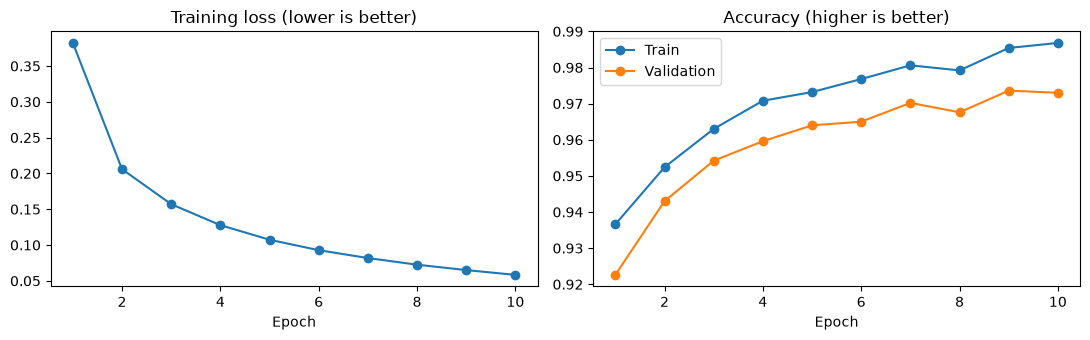

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
epochs = range(1, len(history["loss"]) + 1)

ax1.plot(epochs, history["loss"], marker="o")
ax1.set_title("Training loss (lower is better)")
ax1.set_xlabel("Epoch")

ax2.plot(epochs, history["train_acc"], marker="o", label="Train")
ax2.plot(epochs, history["val_acc"], marker="o", label="Validation")
ax2.set_title("Accuracy (higher is better)")
ax2.set_xlabel("Epoch")
ax2.legend()

plt.tight_layout()
plt.show()

If the train and validation lines stay close, the model is **generalising**: it learned what digits look like, not just memorised the training images. If train keeps climbing while validation stalls or drops, that is **overfitting**.

## 5. The Final Exam: The Test Set

Now, and only now, we use the 10 000 test images. The model has never seen them, and we did not use them to make any decisions. This number is our honest estimate of how well it will do in the real world.

In [11]:
test_acc = accuracy(params, X_test, y_test)
print(f"Test accuracy: {test_acc:.2%}")

Test accuracy: 97.58%


### Where does it go wrong?

A single accuracy number hides a lot. A **confusion matrix** shows, for each true digit (rows), what the model predicted (columns). Everything off the diagonal is a mistake.

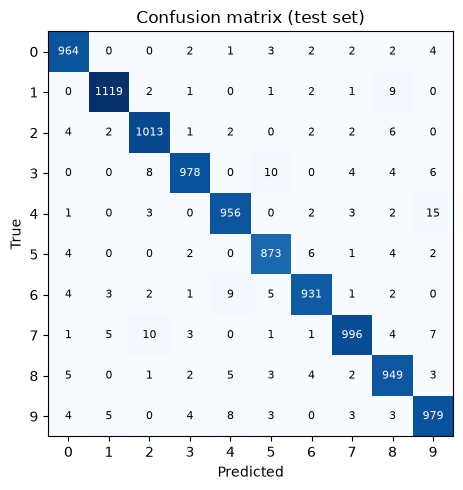

True 4 predicted as 9: 15 times
True 7 predicted as 2: 10 times
True 3 predicted as 5: 10 times


In [12]:
preds = forward(params, X_test)[0].argmax(axis=1)

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_test, preds), 1)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(confusion, cmap="Blues")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
for i in range(10):
    for j in range(10):
        ax.text(j, i, confusion[i, j], ha="center", va="center", fontsize=8,
                color="white" if confusion[i, j] > confusion.max() / 2 else "black")
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.show()

# Which mix-ups are most common?
off_diag = confusion.copy()
np.fill_diagonal(off_diag, 0)
for flat in off_diag.ravel().argsort()[::-1][:3]:
    t, p = divmod(flat, 10)
    print(f"True {t} predicted as {p}: {off_diag[t, p]} times")

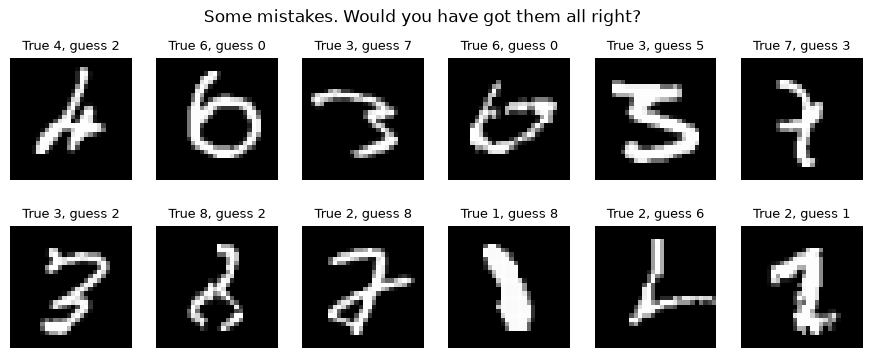

In [16]:
wrong = np.where(preds != y_test)[0][:12]
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(X_test_raw[i], cmap="gray")
    ax.set_title(f"True {y_test[i]}, guess {preds[i]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Some mistakes. Would you have got them all right?")
# plt.tight_layout()
plt.show()

## 6. Your Turn

Some ideas to play with. Change one thing at a time and see what happens to the validation accuracy:

- [ ] Change `lr` to `1.0` or `0.001`. What happens to the loss curve?
- [ ] Change the hidden layer from 128 to 32 or 512 neurons (`init_params(n_hidden=...)`).
- [ ] Train for 30 epochs. Does validation accuracy keep improving, or does it start to overfit?
- [ ] Remove the ReLU (replace `relu(z1)` with just `z1`). How good can a network of straight lines get?
- [ ] Add a second hidden layer. You will need to extend `init_params`, `forward` and `backward`.

When you are done, it is a great exercise to rebuild the same network in PyTorch or Keras. You will find it takes about 15 lines, and now you know exactly what those lines are doing behind the scenes.